**Name:** Yasir Alghamdi
**ID:** 2230004157
**Section:** 9MA2
**Lab** : 10


---

# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

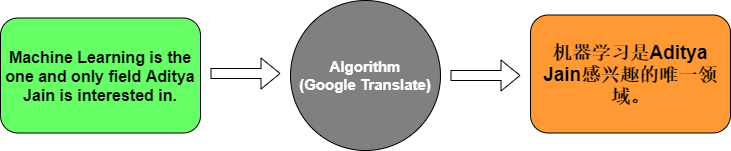

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [1]:
!pip install tensorflow

In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [3]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [5]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [6]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step - accuracy: 0.0000e+00 - loss: 2.4861 - val_accuracy: 0.0000e+00 - val_loss: 2.4861
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.1429 - loss: 2.4783 - val_accuracy: 0.0000e+00 - val_loss: 2.4880
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.4286 - loss: 2.4704 - val_accuracy: 0.0000e+00 - val_loss: 2.4901
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.5714 - loss: 2.4619 - val_accuracy: 0.0000e+00 - val_loss: 2.4923
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.5714 - loss: 2.4524 - val_accuracy: 0.0000e+00 - val_loss: 2.4949
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.5714 - loss: 2.4414 - val_accuracy: 0.0000e+00 - val_loss: 2.4977
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.5714 - loss: 2.4287 - val_accuracy: 0.0000e+00 - val_loss: 2.5010
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.5714 - loss: 2.4136 - val_accura

In [7]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 253ms/step
Input: How are you?
Translation: comment va va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


#### Answers

1. **Embedding layer:** it turns each integer word index into a dense, learnable vector (here 64 numbers). Unlike a raw index, the vector can place words with similar meaning/usage close together, so the network gets a meaningful numeric representation of each word. Index 0 (padding) is just another row in the lookup table.
2. **Encoder LSTM:** it reads the English sequence one word at a time and keeps a memory (hidden/cell state) of what it has seen. With `return_sequences=False` it outputs only the final state, a single 64-dim vector that summarizes the whole source sentence (the "context vector").
3. **Decoder LSTM:** `RepeatVector` copies the context vector once per output position; the decoder LSTM (`return_sequences=True`) then processes these steps and emits one hidden state per target position, i.e. it unrolls the summary into a sequence of French-word representations.
4. **Softmax:** the final `Dense` produces one score per French vocabulary word at each time step. Softmax converts those scores into a probability distribution (values in 0-1 summing to 1), so we can pick the most probable word with `argmax` and train with cross-entropy loss.


### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

### Task 2 solution: English -> French translation on the Kaggle dataset

Download `eng_french.csv` from the Kaggle link above and put it next to this notebook (or set `DATA_PATH`). Steps: load, clean, tokenize, pad, train the encoder-decoder LSTM, evaluate, translate.

In [9]:
import os, re
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

DATA_PATH = "eng_-french.csv"
N_SAMPLES = 20000
MAX_WORDS = 8

df = pd.read_csv(DATA_PATH)
df.columns = ["english", "french"]
print(df.shape)
df.head()

(175621, 2)


,english,french
0,Hi.,Salut!
1,Run!,Cours !
2,Run!,Courez !
3,Who?,Qui ?
4,Wow!,Ça alors !


In [10]:
# Clean: lowercase, strip punctuation, drop NaNs/duplicates, keep short sentences
def clean(s):
    s = str(s).lower().strip()
    return re.sub(r"[^\w\s']", "", s, flags=re.UNICODE)

df = df.dropna().drop_duplicates()
df["english"] = df["english"].map(clean)
df["french"] = df["french"].map(clean)
df = df[(df.english.str.split().str.len() <= MAX_WORDS) & (df.french.str.split().str.len() <= MAX_WORDS)]
df = df.sample(n=min(N_SAMPLES, len(df)), random_state=42).reset_index(drop=True)
english_sentences = df.english.tolist()
french_sentences = df.french.tolist()
print(len(df)); df.head()

20000


,english,french
0,can i have this donut,puisje avoir ce beignet
1,i will never have a daughter,je n'aurai jamais de fille
2,i have a date,j'ai un rendezvous galant
3,i read it to my family,je l'ai lue à ma famille
4,it is a love song,c'est une chanson d'amour


In [11]:
# Tokenize + pad (same approach as the demo above)
tok_eng = Tokenizer(); tok_eng.fit_on_texts(english_sentences)
tok_frn = Tokenizer(); tok_frn.fit_on_texts(french_sentences)

eng_padded = pad_sequences(tok_eng.texts_to_sequences(english_sentences))
frn_padded = pad_sequences(tok_frn.texts_to_sequences(french_sentences))

eng_vocab = len(tok_eng.word_index) + 1
frn_vocab = len(tok_frn.word_index) + 1
print("English vocab:", eng_vocab, "French vocab:", frn_vocab)
print("Shapes:", eng_padded.shape, frn_padded.shape)

English vocab: 5901 French vocab: 10920
Shapes: (20000, 8) (20000, 8)


In [13]:
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=eng_vocab, output_dim=128),
    tf.keras.layers.LSTM(256),                                   # encoder
    tf.keras.layers.RepeatVector(frn_padded.shape[1]),
    tf.keras.layers.LSTM(256, return_sequences=True),            # decoder
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(frn_vocab, activation="softmax"))
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_2 (RepeatVector)  │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_2              │ ?                      │   0 (unbuilt) │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [14]:
history = model.fit(eng_train, np.expand_dims(frn_train, -1),
                    epochs=20, batch_size=64, validation_split=0.2)

loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f"Test loss: {loss:.4f}  Test token accuracy: {accuracy:.4f}")

Epoch 1/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 75s 363ms/step - accuracy: 0.3303 - loss: 5.7369 - val_accuracy: 0.3324 - val_loss: 5.4009
Epoch 2/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 78s 345ms/step - accuracy: 0.3321 - loss: 5.2467 - val_accuracy: 0.3324 - val_loss: 5.3610
Epoch 3/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 74s 370ms/step - accuracy: 0.3321 - loss: 5.1720 - val_accuracy: 0.3324 - val_loss: 5.2962
Epoch 4/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 74s 370ms/step - accuracy: 0.3320 - loss: 5.0830 - val_accuracy: 0.3324 - val_loss: 5.2050
Epoch 5/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 82s 369ms/step - accuracy: 0.3321 - loss: 4.9908 - val_accuracy: 0.3324 - val_loss: 5.1441
Epoch 6/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 74s 368ms/step - accuracy: 0.3321 - loss: 4.9349 - val_accuracy: 0.3324 - val_loss: 5.1015
Epoch 7/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 75s 373ms/step - accuracy: 0.3321 - loss: 4.8856 - val_accuracy: 0.3324 - val_loss: 5.0688
Epoch 8/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 69s 345ms/step - accuracy: 0.3321 - loss: 4

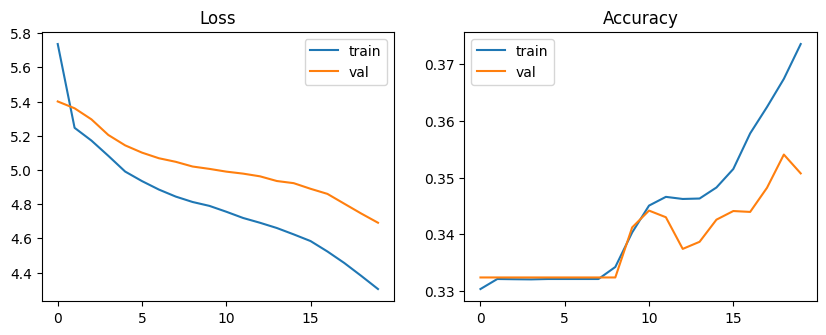

In [15]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(history.history["loss"], label="train"); ax[0].plot(history.history["val_loss"], label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train"); ax[1].plot(history.history["val_accuracy"], label="val"); ax[1].set_title("Accuracy"); ax[1].legend()
plt.show()

In [16]:
def translate(sentence):
    seq = tok_eng.texts_to_sequences([clean(sentence)])
    pad = pad_sequences(seq, maxlen=eng_padded.shape[1])
    ids = np.argmax(model.predict(pad, verbose=0), axis=-1)[0]
    return " ".join(tok_frn.index_word[i] for i in ids if i != 0)

for s in ["Hello", "How are you", "I love you", "Where is the library", "Thank you very much"]:
    print(f"{s!r:28} -> {translate(s)}")

'Hello'                      -> est la
'How are you'                -> 
'I love you'                 -> pas pas
'Where is the library'       -> est est est
'Thank you very much'        -> à


In [17]:
# Optional: BLEU on a few test sentences
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
refs, hyps = [], []
for e, f in list(zip(df.english, df.french))[:200]:
    refs.append([f.split()]); hyps.append(translate(e).split())
print("BLEU:", corpus_bleu(refs, hyps, smoothing_function=SmoothingFunction().method1))

BLEU: 0.002453999129623214


**Discussion:** this plain encoder-decoder squeezes the whole sentence into one 256-d vector and predicts all words independently, so it works on short, common phrases but degrades on long or rare ones. For the e-commerce use case, improvements would be: attention or a Transformer (e.g. a pretrained MarianMT/T5 model), subword tokenization for rare product terms, a much larger parallel corpus, and domain fine-tuning on product listings and reviews.